# Music and the Brain 
---
__Anatomical image__ <br>
- sub-01_ses-01_T1 <br>
_"EchoTime"_ -> TE = 0.0035, <br>
_"RepetitionTime"_ -> TR = 2.53, <br>
<br>
- sub-01_ses-01_T2 <br>
_"EchoTime"_ -> TE = 0.408,, <br>
_"RepetitionTime"_ -> TR = 3.2, <br>


## 0. Setup
### Importing packages

In [331]:
import os #to read the directories

import numpy as np
import pandas as pd

import nibabel as nib

import nilearn
from nilearn import plotting
from nilearn import image
from nilearn.plotting import plot_anat, plot_img, plot_stat_map


## 0.1 Locating and loading data

In [332]:

# Print the current working directory
print("Current working directory:")
print(os.getcwd())

Current working directory:
/Users/brunoleitao/Documents/GitHub/brainplayback_fc_mvpa/scripts


Select the participant id / folder.

In [333]:
# Set the participant and session IDs
part_id = 'sub-08'
ses_id = 'ses-01'

space_id = 'MNI152'

# All data of this participant is in the data directory and in the BIDS format
# The data directory is in the parent directory of this script

src_dir = os.path.join('..', 'data')

### 0.1.1 Anatomical data in the BIDS format

In [334]:

# Path to the anat data
anat_path = os.path.join(src_dir, part_id, ses_id, 'anat')

# listar all files in the anat directory
# and filter for the ones that end with nii.gz
anat_runs = os.listdir(anat_path) 
file_paths_anat = [f for f in anat_runs if f.endswith('T1w.nii.gz')]

In [335]:
# print the paths of the anatomical files
# and the number of files
print("Anatomical files:")
print(file_paths_anat)

print("Number of anatomical files:")
print(len(file_paths_anat))


Anatomical files:
['sub-08_ses-01_desc-preproc_T1w.nii.gz', 'sub-08_ses-01_space-MNI152NLin2009cAsym_res-2_desc-preproc_T1w.nii.gz']
Number of anatomical files:
2


In [336]:
# find the anat image in the space space_id 
# for each filname in file_paths_anat find the space_id a select the one that matches

anat_img = None
for f in file_paths_anat:
    if space_id in f:
        anat_img = os.path.join(anat_path, f)
        # print the path of the anatomical image
        print("Anatomical image:")
        print(anat_img)
        break


Anatomical image:
../data/sub-08/ses-01/anat/sub-08_ses-01_space-MNI152NLin2009cAsym_res-2_desc-preproc_T1w.nii.gz


### 0.1.2 functional data in the BIDS format

In [337]:
func_path = os.path.join(src_dir, part_id, ses_id, 'func')

files_paths_func = os.listdir(func_path)

file_paths_func  = [f for f in files_paths_func if f.endswith('bold.nii.gz')]

# add complete path to the functional images
file_paths_func = [os.path.join(func_path, f) for f in file_paths_func]

# rpint the paths of the functional files
print("Functional files:")
print(file_paths_func)
print("Number of functional files:")
print(len(file_paths_func))

Functional files:
['../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz']
Number of functional files:
4


### 0.1.2.1 functional behavioral labels in the BIDS format

In [338]:
# events files
events_files = [f for f in files_paths_func if f.endswith('events.tsv')]
# print the paths of the events files
print("Events files:")  
print(events_files)
print("Number of events files:")
print(len(events_files))



# add complete path to the events files
events_files = [os.path.join(func_path, f) for f in events_files]

Events files:
['sub-08_ses-01_task-02a_run-3_events.tsv', 'sub-08_ses-01_task-02a_run-4_events.tsv', 'sub-08_ses-01_task-02a_run-1_events.tsv', 'sub-08_ses-01_task-02a_run-2_events.tsv']
Number of events files:
4


## 0.3 Anatomical Data Processing and Plotting

In [339]:
anat_img

'../data/sub-08/ses-01/anat/sub-08_ses-01_space-MNI152NLin2009cAsym_res-2_desc-preproc_T1w.nii.gz'

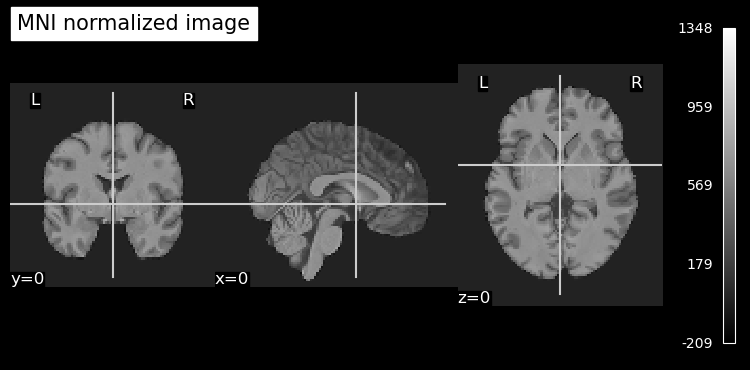

In [340]:
plot_anat(anat_img, 
          title='MNI normalized image' , 
          colorbar=True, 
          cbar_tick_format="%i", 
          cut_coords=(0, 0, 0), 
          display_mode='ortho', 
          draw_cross=True, 
          annotate=True, 
          black_bg=True)
    

In [341]:
#view = plotting.view_img(anat_img, threshold=0.5, colorbar=True, cmap='gray', title='MNI normalized image', cut_coords=(0, 0, 0), draw_cross=True, annotate=True)
#view.open_in_browser()

## 0.3 Functional Data Processing and Plotting


In [342]:
from nilearn.image import concat_imgs, mean_img

/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/2113487633.py:2: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  mean_func_img = mean_img(file_paths_func)


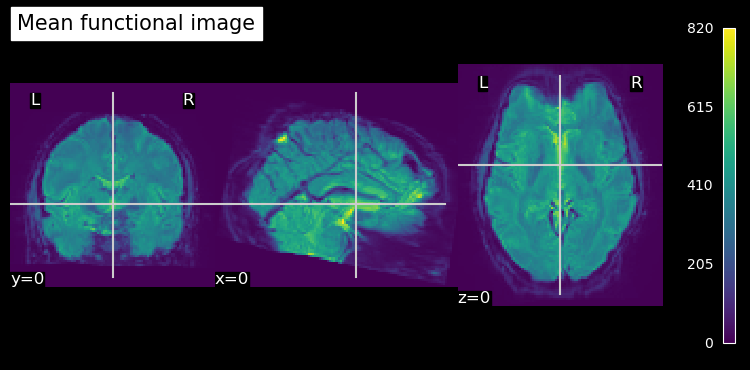

In [343]:
# compute the mean image of the functional images
mean_func_img = mean_img(file_paths_func)

# plot the mean image
plot_img(mean_func_img, title='Mean functional image', colorbar=True, cbar_tick_format="%i", cut_coords=(0, 0, 0), display_mode='ortho', draw_cross=True, annotate=True, black_bg=True)

In [344]:
#view = plotting.view_img(mean_func_img, threshold=0.5, colorbar=True,  cut_coords=(0, 0, 0), draw_cross=True, annotate=True, black_bg=True)
#view.open_in_browser()

## 0.4 Creation of Input dataset and Target vectors 

In [345]:
from nilearn.image import index_img 

In [346]:
# confirm the number of functional images and events files
print("Number of functional images:")
print(len(file_paths_func))
print("Number of events files:")
print(len(events_files))

# check if each functional image has a corresponding events file (search for run_id)
# get the run_id from the functional images
run_ids = [f.split('_')[3] for f in file_paths_func]

# save the run_ids that have both files in a list
run_ids_with_events = []


# check if the run_id is in the events files
for run_id in run_ids:
    print(run_id)
    if any(run_id in e_fn for e_fn in events_files):
        print(f"Run ID {run_id} found in events files")
        run_ids_with_events.append(run_id)

    else:
        print(f"Run ID {run_id} not found in events files")


Number of functional images:
4
Number of events files:
4
run-1
Run ID run-1 found in events files
run-2
Run ID run-2 found in events files
run-4
Run ID run-4 found in events files
run-3
Run ID run-3 found in events files


In [347]:

# create a list of functional images and events files that match the run_id
f_func = []
f_events = []
for run_id in run_ids_with_events:
    # get the functional image that matches the run_id
    f_func.append([f for f in file_paths_func if run_id in f][0])
    
    # get the events file that matches the run_id
    f_events.append([f for f in events_files if run_id in f][0])

# print the functional images and events files that match the run_id
print("Functional images that match the run_id:")
print(f_func)
print("Events files that match the run_id:")
print(f_events)

Functional images that match the run_id:
['../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz']
Events files that match the run_id:
['../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_events.tsv', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_events.tsv', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_events.tsv', '../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_events.tsv']


In [348]:
def get_events(events_fn):
    # read the events file
    events_df = pd.read_csv(events_fn, sep='\t')
    return events_df

In [349]:
# define an offset for the HRF
# this is the time between the event and the response
hrf_offset = 4

block_size = 6 # seconds

In [350]:
# initialize the lists to store the functional images, target (label) an run_id - participant level (p_)

p_func = []
p_target = []
p_run = []

# for each run_id get the functional image and events file
for i, run_id in enumerate(run_ids_with_events):

    # get the functional image
    fn_func = f_func[i]
    # print(fn_func)

    # get events from the events file
    fn_events = f_events[i]

    events = get_events(fn_events)
    # print(events)

    # print the functional image and events file
    print(f"Run ID: {run_id}")

    print(f"Functional image: {fn_func}")

    # load the functional images
    func_img = nib.load(fn_func)
    
    print(f"Events file: {fn_events}")


    # for each event get the onset and duration
    for index, row in events.iterrows():

        # get the onset and duration
        onset = row['onset']
        duration = row['duration']
        trial_type = row['trial_type']

        if trial_type in ['Tenderness',
                           'Wonder', 
                           'Nostalgia', 
                           'Peacefulness', 
                           'Transcendence', 
                           'Sadness', 
                           'Power',
                           'Tension',
                           'JoyfulActivation',]:
            # print the run_id, onset, duration and trial_type
            # this is for debugging purposes
            # to see if the events are correctly loaded
            # and if the functional images are correctly indexed
      

            print(f"Run ID: {run_id}, Onset: {onset}, Duration: {duration}, Trial type: {trial_type}")

            # get two images: one for the first 6 seconds and one for the next 6 seconds


            # block 1
            # get the image indexes for the first block (onset + hrf_offset to onset + hrf_offset + block_size)
            block1_idxs = np.arange(int(onset) + hrf_offset, int(onset) + hrf_offset + block_size)

            # get the image index for the onset
            event1_img = mean_img(index_img(func_img, block1_idxs))

            # add to the lists
            p_func.append(event1_img)
            p_target.append(trial_type)
            p_run.append(run_id)

            # block 2
            # get the image indexes for the second block (onset + hrf_offset + block_size to onset + hrf_offset + 2 * block_size)
        
            block2_idxs = np.arange(int(onset) + hrf_offset + block_size, int(onset) + hrf_offset + 2 * block_size)

            # get the image index for the onset
            event2_img = mean_img(index_img(func_img, block2_idxs))

            # add to the lists
            p_func.append(event2_img)
            p_target.append(trial_type)
            p_run.append(run_id)


            print(f"Functional image: {fn_func}, Target: {trial_type}, Run ID: {run_id}")

# print the number of functional images, targets and run_ids
print("Number of functional images:")
print(len(p_func))

print("Number of targets:")
print(len(p_target))

print("Number of run_ids:")
print(len(p_run))

    

Run ID: run-1
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz
Events file: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_events.tsv
Run ID: run-1, Onset: 12.19, Duration: 24.08, Trial type: Wonder


/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:64: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event1_img = mean_img(index_img(func_img, block1_idxs))
/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:77: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event2_img = mean_img(index_img(func_img, block2_idxs))


Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Wonder, Run ID: run-1
Run ID: run-1, Onset: 42.29, Duration: 24.03, Trial type: Wonder
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Wonder, Run ID: run-1
Run ID: run-1, Onset: 84.24, Duration: 24.17, Trial type: Nostalgia
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Nostalgia, Run ID: run-1
Run ID: run-1, Onset: 114.19, Duration: 24.06, Trial type: Nostalgia
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-1_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Nostalgia, Run ID: run-1
Run ID: run-1, Onset: 156.18, Duration: 24.12, Trial type: Transcendence
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run

/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:64: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event1_img = mean_img(index_img(func_img, block1_idxs))
/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:77: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event2_img = mean_img(index_img(func_img, block2_idxs))


Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Nostalgia, Run ID: run-2
Run ID: run-2, Onset: 42.25, Duration: 24.0, Trial type: Nostalgia
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Nostalgia, Run ID: run-2
Run ID: run-2, Onset: 84.25, Duration: 24.03, Trial type: JoyfulActivation
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: JoyfulActivation, Run ID: run-2
Run ID: run-2, Onset: 114.25, Duration: 24.01, Trial type: JoyfulActivation
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-2_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: JoyfulActivation, Run ID: run-2
Run ID: run-2, Onset: 156.25, Duration: 24.12, Trial type: Sadness
Functional image: ../data/sub-08/ses-01/f

/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:64: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event1_img = mean_img(index_img(func_img, block1_idxs))
/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:77: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event2_img = mean_img(index_img(func_img, block2_idxs))


Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Tenderness, Run ID: run-4
Run ID: run-4, Onset: 42.24, Duration: 24.04, Trial type: Tenderness
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Tenderness, Run ID: run-4
Run ID: run-4, Onset: 84.26, Duration: 23.98, Trial type: Power
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Power, Run ID: run-4
Run ID: run-4, Onset: 114.25, Duration: 24.0, Trial type: Power
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Power, Run ID: run-4
Run ID: run-4, Onset: 156.24, Duration: 24.0, Trial type: Nostalgia
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-4_space-M

/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:64: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event1_img = mean_img(index_img(func_img, block1_idxs))
/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/280245499.py:77: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  event2_img = mean_img(index_img(func_img, block2_idxs))


Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Tenderness, Run ID: run-3
Run ID: run-3, Onset: 42.26, Duration: 24.0, Trial type: Tenderness
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Tenderness, Run ID: run-3
Run ID: run-3, Onset: 84.25, Duration: 23.99, Trial type: Nostalgia
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Nostalgia, Run ID: run-3
Run ID: run-3, Onset: 114.25, Duration: 24.07, Trial type: Nostalgia
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-01_task-02a_run-3_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.nii.gz, Target: Nostalgia, Run ID: run-3
Run ID: run-3, Onset: 156.26, Duration: 23.99, Trial type: JoyfulActivation
Functional image: ../data/sub-08/ses-01/func/sub-08_ses-0

In [351]:
src_dir

'../data'

In [352]:
# save the functional images to a nii image, and the targets and run_ids to csv files


# create a new directory to save the images
output_dir = os.path.join(src_dir, 'derivatives', 'nilearn')

# create the directory if it does not exist
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# create a new directory for the participant
if not os.path.exists(os.path.join(output_dir, part_id)):
    os.makedirs(os.path.join(output_dir, part_id))

# create a new directory for the session
if not os.path.exists(os.path.join(output_dir, part_id, ses_id)):
    os.makedirs(os.path.join(output_dir, part_id, ses_id))

# save the functional images to a nii image 
output_func_img = os.path.join(output_dir, f"{part_id}", f"{ses_id}", f"{part_id}_{ses_id}_task-2a_mvpa_data-wholeblock-2events.nii.gz")

nib.save(nib.concat_images(p_func), output_func_img)

# save the targets to a csv file
output_target = os.path.join(output_dir, f"{part_id}", f"{ses_id}", f"{part_id}_{ses_id}_task-2a_mvpa_target-2events.csv")
df_target = pd.DataFrame(p_target, columns=['target'])
df_target.to_csv(output_target, index=False)
# save the run_ids to a csv file
output_run = os.path.join(output_dir, f"{part_id}", f"{ses_id}", f"{part_id}_{ses_id}_task-2a_mvpa_run-2events.csv")
df_run = pd.DataFrame(p_run, columns=['run_id'])
df_run.to_csv(output_run, index=False)




In [353]:
# plot the mean functional image for the idxs of target 'Tenderness'
tenderness_idxs = [i for i, t in enumerate(p_target) if t == 'Tenderness']
tenderness_imgs = [p_func[i] for i in tenderness_idxs]

# print the number of images for the target 'Tenderness'
print("Number of images for the target 'Tenderness':")
print(tenderness_idxs)



Number of images for the target 'Tenderness':
[24, 25, 26, 27, 60, 61, 62, 63, 72, 73, 74, 75, 108, 109, 110, 111]


/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_79356/1544983969.py:2: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  mean_tenderness_img = mean_img(tenderness_imgs)


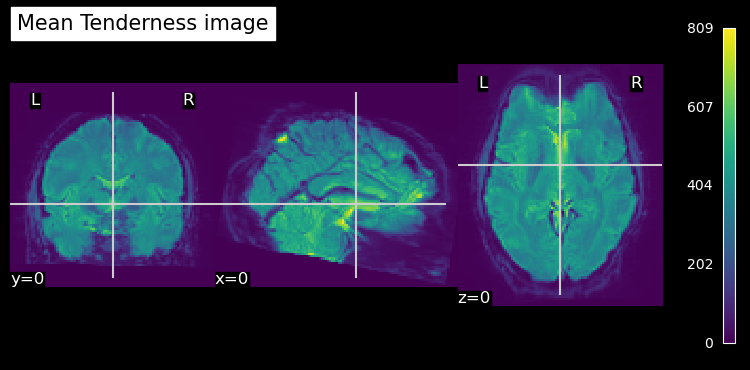

In [354]:
# compute the mean image of the tenderness images
mean_tenderness_img = mean_img(tenderness_imgs)
# plot the mean tenderness image
plot_img(mean_tenderness_img, 
          title='Mean Tenderness image', 
          colorbar=True, 
          cbar_tick_format="%i", 
          cut_coords=(0, 0, 0), 
          display_mode='ortho', 
          draw_cross=True, 
          annotate=True, 
          black_bg=True)